## Introducción

Como analista de datos, tu objetivo es **evaluar cómo la movilidad urbana se relaciona con la productividad económica en las principales ciudades latinoamericanas**.
Para ello trabajarás con datos reales de TomTom Traffic Index y OECD Cities, que deberás limpiar, combinar y analizar para identificar en qué ciudades conviene invertir en infraestructura de transporte.

## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de ambos datasets**.
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯Objetivo:**
Importar las librerías necesarias, cargar los archivos CSV en DataFrames y realizar una revisión preliminar para entender su contenido.

**Instrucciones:**
- Importa las librerías `pandas`, `numpy`, `seaborn` y `matplotlib.pyplot`.
- Carga los archivos usando `pd.read_csv()`:
  - `'/datasets/tomtom_traffic.csv'`
  - `/datasets/oecd_city_economy.csv` `.
- Guarda los DataFrames en las variables `traffic` y `eco`.
- Muestra las primeras 5 filas de cada DataFrame.


In [ ]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:

# cargar archivos
traffic = pd.read_csv("/datasets/tomtom_traffic.csv")
eco = pd.read_csv("/datasets/oecd_city_economy.csv")

In [ ]:
# mostrar las primeras 5 filas de traffic
traffic.head()

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [ ]:
# mostrar las primeras 5 filas de eco
eco.head()

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"


**Tip:** Si no usas `print()` la tabla se vera mejor.


---

## 🧩Paso 2: Explorar, limpiar y preparar los datos

Antes de combinar los datasets, inspecciona su estructura, tipos de datos, columnas y valores faltantes.
Anota las columnas que necesiten limpieza y luego estandariza los nombres de columnas.

### 2.1 Explorar la estructura y tipos de datos

**🎯Objetivo:**
Identificar columnas con tipos incorrectos, distribución y nulos, anotar las columnas que requieren conversión.

**Instrucciones:**

- Usa `.info()` para conocer la estructura de ambos DataFrames.
- Muestra los primeros 3 renglones de cada DF.
- Identifica si los detalles de cada DF estan bien o si requieren correcciones y escribe tus conclusiones en el bloque Markdown.
  - ¿Hay columnas que requieren conversión?¿ Cuáles son? ¿Que tipo de dato ienen y cuál deberían de tener?
  - ¿Hay datos ausentes en alguna columna?


In [ ]:
# Examinar la estructura de traffic
traffic.info()
traffic.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232


En la estructura del DF traffic, se observa que:
- Las columnas `UpdateTimeUTC` y `UpdateTimeUTCWeekAgo` son de tipo ...
- Las columnas update_time_utc y UpdateTimeUTCWeekAgo son de tipo object y deberían convertirse a tipo datetime.
No se observan datos ausentes, ya que todas las columnas tienen 1,004,464 valores no nulos.

In [ ]:
# Examinar la estructura de eco
eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"


En la estructura del DF eco, se observa que:
- Las columnas `City GDP/capita`, `Unemployment %`, ...
- Las columnas City GDP/capita, Unemployment %, PM2.5 (µg/m³) y Population (M) son de tipo object, pero representan valores numéricos, por lo que requieren limpieza y conversión a tipo numérico.
No se observan datos ausentes, ya que todas las columnas tienen 30 valores no nulos.

### 2.2 Renombrar columnas

**🎯Objetivo:**
Estandarizar los nombres de columnas para evitar errores y facilitar la unión de los datasets.

**Instrucciones:**

- Cambia los nombres de las columnas para que tengan el formato `snake_case`.
    - `Country` → `country`
    - `UpdateTimeUTC` → `update_time_utc`
- Verifica que los cambios se hayan aplicado correctamente usando `.columns`.


In [ ]:
# Estandarizar los nombres de las columnas de traffic
traffic = traffic.rename(columns={
    "Country": "country",
    "City": "city",
    "UpdateTimeUTC": "update_time_utc",
    "JamsDelay": "jams_delay",
    "TrafficIndexLive": "traffic_index_live",
    "JamsLengthInKms": "jams_length_kms",
    "JamsCount": "jams_count",
    "TrafficIndexWeekAgo": "traffic_index_week_ago",
    "UpdateTimeUTCWeekAgo": "update_time_utc_week_ago",
    "TravelTimeLivePer10KmsMins": "travel_time_live_per_10kms_mins",
    "TravelTimeHistoricPer10KmsMins": "travel_time_hist_per_10kms_mins",
    "MinsDelay": "mins_delay"
})

# verificar cambios
traffic.columns

Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'jams_length_kms', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_per_10kms_mins', 'travel_time_hist_per_10kms_mins',
       'mins_delay'],
      dtype='object')

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 2)</b>
Rename de traffic correcto: diccionario explícito con las 12 columnas, incluyendo <code>update_time_utc_week_ago</code>. La conversión de fechas (celda 23) corre DESPUÉS del rename. ✅
</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor. (Iteración 1)</b>
El rename de traffic está dividido en dos celdas:
<ul>
<li><b>Celda 14</b> (exec=8): renombra solo 2 de 12 columnas (<code>Country</code> y <code>UpdateTimeUTC</code>).</li>
<li><b>Celda 25</b> (exec=26): renombra las 10 columnas restantes.</li>
</ul>

Esto crea un problema: la <b>celda 18</b> (conversión de fechas, exec=37) usa <code>traffic['update_time_utc_week_ago']</code>, pero ese nombre solo existe después de que corra la celda 25. En la sesión actual funcionó porque las celdas corrieron en un orden distinto al del notebook. Sin embargo, si haces <b>Restart & Run All</b>, la celda 18 fallará con <code>KeyError: 'update_time_utc_week_ago'</code>.

<b>Solución:</b> consolida el rename completo (las 12 columnas) en una sola celda, ANTES de la celda de conversión de fechas. Puedes combinar los diccionarios de las celdas 14 y 25 en un solo bloque.
</div>

In [ ]:

# Estandarizar los nombres de las columnas de eco
eco = eco.rename(columns={
    "Year": "year",
    "City": "city",
    "Country": "country",
    "City GDP/capita": "city_gdp_capita",
    "Unemployment %": "unemployment_pct",
    "PM2.5 (\u03BCg/m³)": "pm25",
    "Population (M)": "population_m"
})
# verificar cambios
eco.columns

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m'],
      dtype='object')


### 2.3 Corregir formatos numéricos y de fecha

**🎯Objetivo:**
Asegurar que las columnas de fechas y valores numéricos estén en formatos correctos para permitir análisis, cálculos y comparaciones precisas.

**Instrucciones:**

- Convierte las columnas de fecha de `traffic` a formato `datetime`. Haz el cambio a prueba de errores.
- En el dataset `eco`, limpia los valores numéricos:
    - En `city_gdp_capita`: elimina separadores de miles (`.`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `unemployment_pct`: elimina el símbolo de porcentaje (`%`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `population_m`: reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
- Finalmente, crea una nueva columna llamada `population` multiplicando `population_m` por 1,000,000 para obtener la población total.


<details>
<summary>Haz clic para ver la pista</summary>
para eliminar símbolos, puedes reemplazarlos por un texto vacío.

In [ ]:
# Convertir las columnas de traffic a tipo fecha con pd.to_datetime()
traffic['update_time_utc'] = pd.to_datetime(
    traffic['update_time_utc'],
    errors='coerce'
)

traffic['update_time_utc_week_ago'] = pd.to_datetime(
    traffic['update_time_utc_week_ago'],
    errors='coerce'
)

traffic.info()

# verificar el cambio
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                           Non-Null Count    Dtype         
---  ------                           --------------    -----         
 0   country                          1004464 non-null  object        
 1   city                             1004464 non-null  object        
 2   update_time_utc                  1004464 non-null  datetime64[ns]
 3   jams_delay                       1004464 non-null  float64       
 4   traffic_index_live               1004464 non-null  float64       
 5   jams_length_kms                  1004464 non-null  float64       
 6   jams_count                       1004464 non-null  float64       
 7   traffic_index_week_ago           1004464 non-null  float64       
 8   update_time_utc_week_ago         1004464 non-null  datetime64[ns]
 9   travel_time_live_per_10kms_mins  1004464 non-null  float64       
 10  travel_time_hist_per_10kms_min

In [ ]:
# Limpia separadores y convierte columnas numéricas en eco
eco['city_gdp_capita'] = eco['city_gdp_capita'].astype(str).str.replace('.', '', regex=False).str.replace(',', '.', regex=False).astype(float)
eco['unemployment_pct'] = eco['unemployment_pct'].astype(str).str.replace('%', '', regex=False).astype(float)
eco['population_m'] = eco['population_m'].astype(str).str.replace(',', '.', regex=False).astype(float)

# Calcula la población total en unidades absolutas (Multiplica * 1000000)
eco['population'] = eco['population_m'] * 1000000

# verificar el cambio
eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm25              30 non-null     object 
 6   population_m      30 non-null     float64
 7   population        30 non-null     float64
dtypes: float64(4), int64(1), object(3)
memory usage: 2.0+ KB


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
0,2023,buenos-aires,Argentina,15782.0,6.2,"15,2",15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,"29,50",22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,"19,10",13.6,13600000.0



---

## 🧩Paso 3: Extraer año y filtrar

Extraer el año permite filtrar la información y trabajar solo con el período más reciente y relevante.

### 3.1 Extraer columna año y filtrar 2024

**🎯Objetivo**
Identificar el año de cada registro y mantener solo los registros del 2024.

**Intrucciones**

- Como el DataFrame `traffic` no tiene una columna de año, utiliza el atributo `.dt.year` sobre su columna de fecha para crear una nueva columna llamada `year`.
- Filtra las filas donde el año sea **2024**.
- Utiliza `.copy()` para crear dos nuevos DataFrames (`traffic_2024` y `eco_2024`) para evitar modificar el dataset original.

In [ ]:
# Convertir update_time_utc a fecha
traffic['update_time_utc'] = pd.to_datetime(
    traffic['update_time_utc'],
    errors='coerce'
)

# Extraer el año de las fechas en update_time_utc
traffic['year'] = traffic['update_time_utc'].dt.year

# Verificar cambio
traffic.head(3)

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,mins_delay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232,2025


In [ ]:

# Filtro los registros del año 2024
traffic_2024 = traffic[traffic['year'] == 2024].copy()
eco_2024 = eco[eco['year'] == 2024].copy()

# Revisar dataframes nuevos
display(traffic_2024.head())
display(eco_2024.head())

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,mins_delay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30.000,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30.000,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30.000,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30.000,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30.000,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00.000,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00.000,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,"14,50",15.4,15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,"28,00",22.6,22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,"18,40",13.7,13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,"12,80",4.8,4800000.0
19,2024,salvador,Brazil,8899.0,12.4,"15,20",3.9,3900000.0



---

## 🧩Paso 4: Analizar y resumir datos de movilidad

Como el dataset de tráfico contiene **múltiples registros por ciudad**. En esta parte, calcularás los promedios anuales por ciudad para simplificar el análisis y obtener una visión más clara de las tendencias generales.

### 4.1 Calcular promedios de tráfico por ciudad

**🎯Objetivo:**
Obtener una vista consolidada del tráfico promedio por ciudad y año, para analizar patrones generales sin depender de datos diarios.

**Instrucciones**

- Agrupa los datos por `city`, `country` y `year`.
- Calcula el promedio **solo de las métricas de tráfico más relevantes**: como `jams_delay`, `traffic_index_live`, `jams_length_kms`, `jams_count`, `mins_delay`, y tiempos de viaje (`travel_time_live_per_10kms_mins` y `travel_time_hist_per_10kms_mins`).
- Guarda el resultado como `traffic_city_year_2024`, mantén las columnas como variables (no índices).


<details>
<summary>Haz clic para ver la pista</summary>
Usa ".agg()" para aplicar funciones de promedio. Al final, reinicia el índice para mantener las columnas de la agrupación como variables (no índices).

In [ ]:


# Actualizar los datos de 2024 con los nombres de columnas corregidos
traffic["update_time_utc"] = pd.to_datetime(traffic["update_time_utc"], errors="coerce")
traffic["year"] = traffic["update_time_utc"].dt.year
traffic_2024 = traffic[traffic["year"] == 2024].copy()

# Calcular los promedios de tráfico por ciudad, país y año
traffic_city_year_2024 = (
    traffic_2024
    .groupby(["city", "country", "year"])
    .agg({
        "jams_delay": "mean",
        "traffic_index_live": "mean",
        "jams_length_kms": "mean",
        "jams_count": "mean",
        "mins_delay": "mean",
        "travel_time_live_per_10kms_mins": "mean",
        "travel_time_hist_per_10kms_mins": "mean"
    })
    .reset_index()
)

# Mostrar resultado
traffic_city_year_2024.head()

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,0.774172,16.267977,15.493804
1,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,0.792968,13.397861,12.604894
2,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,0.495276,15.219292,14.724016
3,abu-dhabi,ARE,2024,171.157315,13.902028,24.507380,47.268019,0.139764,9.829092,9.689328
4,adana,TUR,2024,83.864761,22.541040,11.827331,23.754620,1.129749,15.879694,14.749945


In [ ]:
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False).head()

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,1.396351,18.505043,17.108691
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,1.325160,17.714139,16.388979
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734


La ciudad con el mayor tiempo promedio de tráfico es México City,México


---

## 🧩Paso 5: Unir movilidad y economía

Combinar datasets te permite analizar cómo se relacionan los indicadores económicos con los de movilidad.

### 5.1 Unir tráfico (tabla principal) con indicadores económicos

**🎯Objetivo:**
Combinar la información de tráfico y economía en un solo DataFrame para analizar cómo las condiciones económicas se relacionan con la movilidad urbana.

**Instrucciones**
- Selecciona solo las **columnas relevantes** de cada dataset (por ejemplo, variables clave de tráfico y de economía).
- Usa `.copy()` al crear subconjuntos para evitar modificar el dataset original.
- Une ambos DataFrames y define como **claves de unión** a `city` y `year`.
- Mantén solo las ciudades y años presentes en ambos datasets.
- Guarda el resultado en una nueva variable llamada `merged` y muestra las primeras 5 filas.


<details>
<summary>Haz clic para ver la pista</summary>
Aplica una unión de tipo "inner" para mantener las ciudades y años presentes en ambos datasets.

In [ ]:
print (eco_2024.columns)

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m', 'population'],
      dtype='object')


<div class="alert alert-block alert-danger">
<b>Comentario del revisor. (Iteración 2)</b>
La celda 39 falla con <code>KeyError: ['PM2.5 (µg/m³)', 'population.m'] not in index</code>.

Causa: al inicio de la celda 39 hay un intento de renombrar eco_2024:
<pre>
eco_2024 = eco_2024.rename(columns={{
    'PM2.5 (µg/m³)': 'pm25',      ← esta columna ya no se llama así
    'population.m': 'population'   ← esta tampoco existe
}})
</pre>

Esas columnas ya fueron renombradas en una celda anterior. Al intentar renombrarlas de nuevo, pandas no las encuentra y lanza KeyError.

<b>Solución:</b> elimina esas dos líneas de rename al inicio de la celda 39. Las columnas <code>pm25</code> y <code>population_m</code> ya tienen los nombres correctos en eco_2024.

Después de eliminarlas, haz <b>Kernel → Restart & Run All</b>.
</div>

In [ ]:


# Seleccionar columnas clave de tráfico y economía
left_cols = [
    'city',
    'country',
    'year',
    'jams_delay',
    'traffic_index_live',
    'jams_length_kms',
    'jams_count',
    'mins_delay',
    'travel_time_live_per_10kms_mins',
    'travel_time_hist_per_10kms_mins'

]
right_cols = [
    "city",
    "year",
    "city_gdp_capita",
    "unemployment_pct",
    "pm25",
    "population_m"
]



# Crear los dos datasets reducidos
traffic_2024_small = traffic_city_year_2024[left_cols].copy()
eco_2024_small = eco_2024[right_cols].copy()


# Unir datasetsmer
merged = traffic_2024_small.merge(
    eco_2024_small,
    on=['city', 'year'],
    how='inner'
)

# Mostrar las primeras 5 filas
merged.head()

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,city_gdp_capita,unemployment_pct,pm25,population_m
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,11124.0,9.5,"16,80",6.1
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,"17,60",11.3
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,16251.0,7.8,"12,80",4.8
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,18117.0,7.2,"14,50",15.4
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,12381.0,8.2,"13,50",3.7


In [ ]:
print (set(right_cols)-set(eco_2024.columns))

set()


In [ ]:
print(eco_2024.columns)

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m', 'population'],
      dtype='object')


In [ ]:
right_cols = [
    "city",
    "year",
    "city_gdp_capita",
    "unemployment_pct",
    eco_2024.columns[5],
    "population_m"
]

print(eco_2024[right_cols].head())

              city  year  city_gdp_capita  unemployment_pct   pm25  \
15    buenos-aires  2024          18117.0               7.2  14,50   
16       sao-paulo  2024          14703.0               8.5  28,00   
17  rio-de-janeiro  2024          13349.0               9.2  18,40   
18        brasilia  2024          16251.0               7.8  12,80   
19        salvador  2024           8899.0              12.4  15,20   

    population_m  
15          15.4  
16          22.6  
17          13.7  
18           4.8  
19           3.9  


In [ ]:
print(set(right_cols) - set(eco_2024.columns))

set()


In [ ]:
eco_2024_small = eco_2024[right_cols].copy()

In [ ]:

right_cols = [
    "city",
    "year",
    "city_gdp_capita",
    "unemployment_pct",
    eco_2024.columns[5],
    "population_m"
]

print(eco_2024[right_cols].head())

              city  year  city_gdp_capita  unemployment_pct   pm25  \
15    buenos-aires  2024          18117.0               7.2  14,50   
16       sao-paulo  2024          14703.0               8.5  28,00   
17  rio-de-janeiro  2024          13349.0               9.2  18,40   
18        brasilia  2024          16251.0               7.8  12,80   
19        salvador  2024           8899.0              12.4  15,20   

    population_m  
15          15.4  
16          22.6  
17          13.7  
18           4.8  
19           3.9  


In [ ]:
print(eco_2024_small.head())

              city  year  city_gdp_capita  unemployment_pct   pm25  \
15    buenos-aires  2024          18117.0               7.2  14,50   
16       sao-paulo  2024          14703.0               8.5  28,00   
17  rio-de-janeiro  2024          13349.0               9.2  18,40   
18        brasilia  2024          16251.0               7.8  12,80   
19        salvador  2024           8899.0              12.4  15,20   

    population_m  
15          15.4  
16          22.6  
17          13.7  
18           4.8  
19           3.9  


In [ ]:
eco_2024 = eco[eco["year"] == 2024].copy()

print(eco_2024.head())

    year            city    country  city_gdp_capita  unemployment_pct   pm25  \
15  2024    buenos-aires  Argentina          18117.0               7.2  14,50   
16  2024       sao-paulo     Brazil          14703.0               8.5  28,00   
17  2024  rio-de-janeiro     Brazil          13349.0               9.2  18,40   
18  2024        brasilia     Brazil          16251.0               7.8  12,80   
19  2024        salvador     Brazil           8899.0              12.4  15,20   

    population_m  population  
15          15.4  15400000.0  
16          22.6  22600000.0  
17          13.7  13700000.0  
18           4.8   4800000.0  
19           3.9   3900000.0  


In [ ]:
merged = traffic_2024_small.merge(
    eco_2024_small,
    on=["city", "year"],
    how="inner"
)

merged.head()

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,city_gdp_capita,unemployment_pct,pm25,population_m
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,11124.0,9.5,"16,80",6.1
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,"17,60",11.3
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,16251.0,7.8,"12,80",4.8
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,18117.0,7.2,"14,50",15.4
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,12381.0,8.2,"13,50",3.7


In [ ]:


print(eco_2024.columns)

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m', 'population'],
      dtype='object')


In [ ]:
right_cols = [
    "city",
    "year",
    "city_gdp_capita",
    "unemployment_pct",
    "pm25",
    "population_m"
]

eco_2024_small = eco_2024[right_cols].copy()

print(eco_2024_small.head())

              city  year  city_gdp_capita  unemployment_pct   pm25  \
15    buenos-aires  2024          18117.0               7.2  14,50   
16       sao-paulo  2024          14703.0               8.5  28,00   
17  rio-de-janeiro  2024          13349.0               9.2  18,40   
18        brasilia  2024          16251.0               7.8  12,80   
19        salvador  2024           8899.0              12.4  15,20   

    population_m  
15          15.4  
16          22.6  
17          13.7  
18           4.8  
19           3.9  


In [ ]:
%whos

Variable                 Type         Data/Info
-----------------------------------------------
eco                      DataFrame        year            city <...>        1.8   1800000.0  
eco_2024                 DataFrame        year            city <...>        1.8   1800000.0  
eco_2024_small           DataFrame                  city  year <...>1.2  \n29           1.8  
left_cols                list         n=10
merged                   DataFrame                  city countr<...>7.1  \n14          22.6  
np                       module       <module 'numpy' from '/.v<...>kages/numpy/__init__.py'>
pd                       module       <module 'pandas' from '/.<...>ages/pandas/__init__.py'>
plt                      module       <module 'matplotlib.pyplo<...>es/matplotlib/pyplot.py'>
right_cols               list         n=6
sns                      module       <module 'seaborn' from '/<...>ges/seaborn/__init__.py'>
traffic                  DataFrame            country       cit<...

In [ ]:
print(eco_2024.columns)

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m', 'population'],
      dtype='object')


In [ ]:
print(eco.columns)

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m', 'population'],
      dtype='object')


In [ ]:
eco_2024 = eco[eco["year"] == 2024].copy()

print(eco_2024.columns)

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m', 'population'],
      dtype='object')


In [ ]:
print(traffic[["city", "update_time_utc", "year"]].head())

        city         update_time_utc  year
0  abu-dhabi 2025-01-13 04:01:30.001  2025
1  abu-dhabi 2025-01-13 03:46:00.000  2025
2  abu-dhabi 2025-01-13 02:46:30.000  2025
3  abu-dhabi 2025-01-13 01:46:30.001  2025
4  abu-dhabi 2025-01-13 00:01:30.000  2025


In [ ]:
print(traffic["year"].value_counts().sort_index())

2024    886779
2025    117685
Name: year, dtype: int64


In [ ]:
traffic_2024 = traffic[traffic["year"] == 2024].copy()

print(traffic_2024.shape)
print(traffic_2024[["city", "year"]].head())

(886779, 13)
          city  year
302  abu-dhabi  2024
303  abu-dhabi  2024
304  abu-dhabi  2024
305  abu-dhabi  2024
306  abu-dhabi  2024



---

## 🧩Paso 6: Visualización y análisis de relaciones

Ahora que tienes un dataset limpio y unificado, es momento de **visualizar patrones**.
Los gráficos te ayudarán a entender cómo se relacionan las variables económicas con las de movilidad urbana.

### 6.1 Visualizar relaciones entre economía y tráfico

**🎯Objetivo:**
Analizar visualmente la distribución y la relación entre indicadores de tráfico y economía en 2024, para identificar posibles patrones o tendencias generales entre ambas variables.

**Instrucciones**
- Usa las librerías `seaborn` y `matplotlib.pyplot` para generar los gráficos.
- Visualiza la distribución del **tráfico** (`jams_delay`) mediante:
    - **Boxplot** → para observar la media, mediana y detectar valores atípicos.
- Visualiza la distribución de la **economía** (`city_gdp_capita`) mediante:
    - **Histograma** → para analizar la forma de la distribución y el valor promedio del PIB per cápita.
- Finalmente, **compara ambas variables**, para observar si existe alguna relación entre ellas, haciendo un solo gráfico de barras donde aparezcan ambos indicadores.
- Recuerda agregar título y etiquetas a los ejes de tus gráficos.
- Observa y comenta los patrones, valores extremos o posibles relaciones que identifiques.

In [ ]:
print(eco_2024.columns)

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m', 'population'],
      dtype='object')


**Tip:** Dentro de los parentesis del boxplot, agrega `showmeans=True` para ver la media en el gráfico.

In [ ]:

print(eco_2024.columns)

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m', 'population'],
      dtype='object')


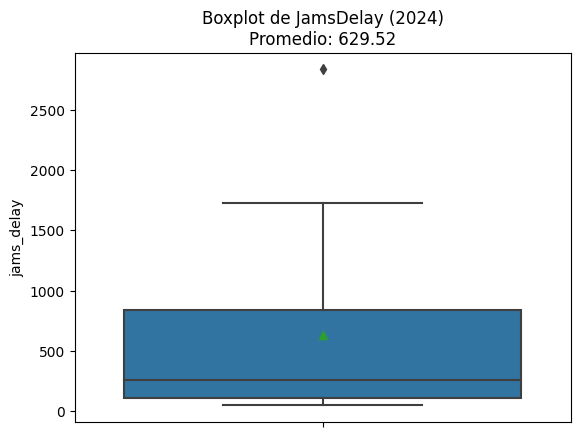

In [ ]:
# Crear boxplot para observar el comportamiento de los minutos de congestion JamsDelay
# crea tu gráfico
sns.boxplot(data=merged, y="jams_delay", showmeans=True)

# obtener promedio para mostrarlo en título
mean_value = merged['jams_delay'].mean()
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}')
plt.show()


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b>
Boxplot con <code>showmeans=True</code>, promedio en título. ✅
</div>

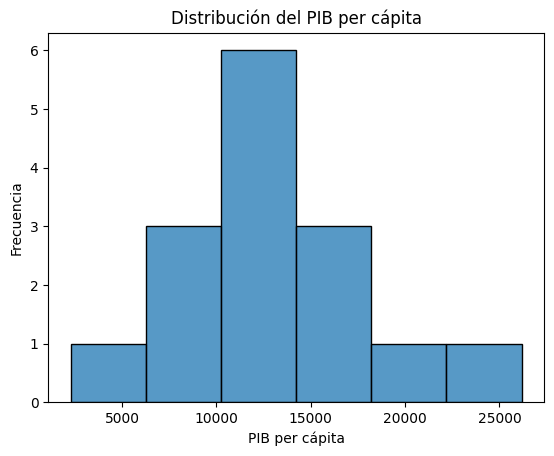

In [ ]:
# Crear histograma para ver la distribución de la economía (city_gdp_capita)
sns.histplot(data=merged, x="city_gdp_capita")
plt.title("Distribución del PIB per cápita")
plt.xlabel("PIB per cápita")
plt.ylabel("Frecuencia")
plt.show()


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b>
Histograma con <code>sns.histplot()</code>, título y etiquetas. ✅ Para próximos proyectos: añade <code>kde=True</code>.
</div>

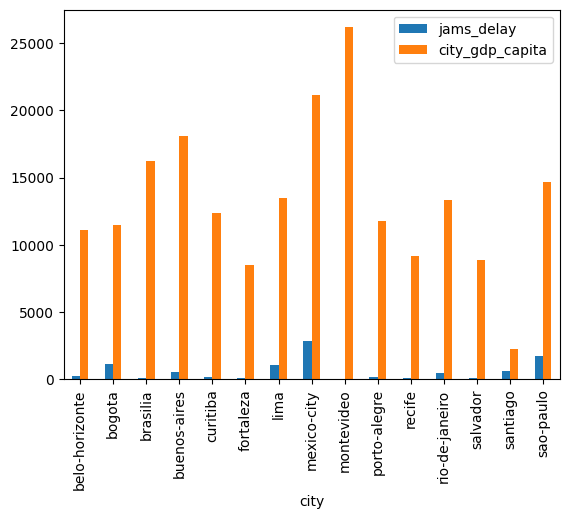

In [ ]:
# Gráfico de barras para comparar jams_delay y city_gdp_capita por ciudad
merged.plot(x="city", y=["jams_delay", "city_gdp_capita"], kind="bar")

plt.xticks(rotation=90)
plt.show()


In [ ]:
print(merged["city_gdp_capita"].dtype)
print(merged["city_gdp_capita"].head())

float64
0    11124.0
1    11442.0
2    16251.0
3    18117.0
4    12381.0
Name: city_gdp_capita, dtype: float64


In [ ]:
print(merged["city_gdp_capita"].head())
print(merged["city_gdp_capita"].dtype)

0    11124.0
1    11442.0
2    16251.0
3    18117.0
4    12381.0
Name: city_gdp_capita, dtype: float64
float64


### 🧠 **Reflexiona**
Excelente trabajo llegando a esta etapa del análisis. Antes de avanzar, revisa tus gráficos, tómate un momento para pensar:

* ¿Las ciudades con mayor PIB per cápita también presentan más congestión?

* ¿O sucede lo contrario, o no existe una relación clara?

No se observa una relación clara entre el PIB per cápita y la congestión. Algunas ciudades con un PIB per cápita alto presentan niveles elevados de congestión, pero este patrón no se mantiene en todas las ciudades. Por lo tanto, con estos datos no podemos afirmar que un mayor PIB per cápita implique mayor congestión.

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b>
Reflexión Paso 6 correcta: "No se observa una relación clara... un mayor PIB per cápita no implica mayor congestión." ✅ Lenguaje no causal apropiado. Para enriquecerla: menciona Montevideo (PIB más alto + congestión mínima) y Ciudad de México (2° PIB + congestión máxima) como los dos ejemplos más elocuentes.
</div>


---

## 🧩Paso 7: Exportar y documentar resultados

En esta etapa final consolidarás todo tu trabajo: guardarás el dataset limpio y crearás un resumen que documente los resultados del proyecto.

### 7.1 Guardar dataset final

**🎯Objetivo:**
Generar un CSV limpio, reproducible y con columnas relevantes para análisis posterior.

**Instrucciones**

- Exporta el DataFrame `merged` con el nombre: `ladb_mobility_economy_2024_clean.csv`
- Usa `index=False` para no incluir el índice.


In [ ]:
# Exporta el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b>
CSV exportado (exec=41). ✅
</div>

Para poder ver o descargar el archivo generado:   
En el menú lateral que esta a la izquierda, ve hasta la parte de abajo, a la sección de **Exportar dataset** para más información.


---

## ✅ Entregables

1. **Notebook `.ipynb`** con todas las celdas (código + comentarios).
2. **CSV final**: `ladb_mobility_economy_2024_clean.csv`.
3. **Resumen ejecutivo breve** en Markdown (3–5 párrafos).



---

# 🧾 Resumen ejecutivo (plantilla)

> Completa este resumen al finalizar el análisis. Mantén 3–5 párrafos cortos, claros y accionables.

**Contexto & objetivo:**  
- Responde la pregunta central del análisis: ¿qué relación existe entre la movilidad urbana (congestión, tiempos de viaje) y la productividad económica (PIB per cápita)?
- Explica brevemente las variables clave utilizadas y su relevancia para la toma de decisiones.

**Cobertura de datos:**  
- Especifica los años analizados, número de ciudades y países incluidos.

**Metodología (alto nivel):**  
- Describe los procesos principales: limpieza de datos (formatos, estandarización de columnas).
- Explica la agregación por ciudad–año y el uso de una unión INNER para integrar tráfico y economía.
- Menciona las validaciones visuales empleadas (distribuciones, outliers, tendencias generales).

**Hallazgos iniciales:**  
- Resume los patrones más importantes entre índices de tráfico y PIB per cápita.
- Destaca anomalías u outliers que podrían requerir revisión adicional o un análisis más profundo.

**Recomendaciones**  
Aterriza los hallazgos en acciones: ciudades prioritarias, necesidad de validar fuentes, requerimiento de análisis adicionales, o propuestas de inversión.

- ¿Qué ciudad : Bogotá, Lima o Buenos Aires o alguna otra en particular, muestra la mayor correlación significativa entre altos niveles de congestión vehicular y bajos indicadores de productividad económica, sugiriendo ser una ciudad prioritaria para inversión en infraestructura de transporte?


El análisis busca explorar la relación entre la movilidad urbana y los indicadores económicos, principalmente el PIB per cápita. Para 2024 se compararon indicadores de congestión, como jams_delay, con city_gdp_capita, con el objetivo de identificar posibles patrones entre el tráfico urbano y las condiciones económicas de las ciudades.

Cobertura y metodología:
Se prepararon y limpiaron los datos de tráfico y economía, estandarizando formatos y tipos de datos. Posteriormente, los datos se agregaron por ciudad y año y se integraron mediante una unión INNER, conservando únicamente las ciudades presentes en ambos datasets. El análisis final se concentró en 2024 y se utilizaron gráficos para estudiar las distribuciones y comparar los indicadores.

Hallazgos:
La comparación visual no muestra una relación directa y consistente entre un mayor PIB per cápita y una mayor congestión. México City presenta el mayor jams_delay entre las ciudades analizadas, pero otras ciudades con PIB per cápita elevado no presentan necesariamente los mayores niveles de congestión. Además, el boxplot mostró valores extremos en la distribución de jams_delay, lo que indica diferencias importantes entre ciudades.

Recomendaciones:
Los resultados sugieren que el PIB per cápita por sí solo no explica las diferencias observadas en la congestión urbana. Para profundizar el análisis sería conveniente incorporar otras variables relacionadas con movilidad, población e infraestructura y calcular medidas estadísticas de asociación antes de concluir que existe una relación entre productividad económica y congestión. Las ciudades con niveles elevados de congestión, como México City, pueden priorizarse para análisis adicionales que permitan identificar los factores asociados a esos niveles.